# Gradiente conjugado frente a GS ponderado: lo que compra un costo explícito

**Pregunta:** ¿Qué compra minimizar un costo explícito con gradiente conjugado (M10) frente al lazo de Gerchberg-Saxton ponderado (M06) en la tarea de 10 x 10 trampas, y cuánto cuesta en iteraciones?

- Nivel: 3, estado del arte. Método ejecutado: M10.
- Requisitos previos: `05-optimization/01-the-cost-and-its-gradient`, que presenta el costo, su gradiente y un primer descenso.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de un minuto.

## Objetivos

El notebook anterior mostró que el gradiente conjugado sobre el costo de un arreglo de trampas es monótono y lento desde fases aleatorias. Un método no se conserva solo por su velocidad: se conserva por lo que puede hacer y los lazos clásicos no. Este notebook mide eso para M10, el método de gradiente conjugado de Harte et al. (2014), frente al lazo ponderado M06 de Di Leonardo et al. (2007). Al terminar puedes:

- refinar un holograma de GS ponderado con M10 y decir qué mejora el costo y qué empeora;
- decir qué cambia el costo con potencia $t = 4$ en la trampa más débil y en la más fuerte;
- pedirle a M10 una eficiencia y leer con qué exactitud se cumple;
- decir dónde está M10 frente al lazo clásico, y con qué ninguna implementación de referencia permite compararlo.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.optim import m10_cg
from pipeline.model.holo.methods.optim._common import TrapCost

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee un caso del archivo de ejemplo `data/examples/cases.json`, escrito por la biblioteca de casos del pipeline y leído con el lector de contrato del propio pipeline.

- Propietario: este repositorio; el caso es sintético, definido por la tarea de calibración de Di Leonardo, Ianni y Ruocco (2007).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C12 (un arreglo cuadrado de 10 x 10 sobre un haz gaussiano).

In [2]:
# el caso C12 del archivo de ejemplo: el montaje óptico y las 100 trampas de la tarea de 10 x 10
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")
print("paso", rec["setup"]["pitch_um"], "um | longitud de onda", rec["setup"]["wavelength_nm"], "nm")

C12_calibration | 100 trampas | SLM 256 x 256 píxeles
paso 20 um | longitud de onda 850 nm


## Método

M10 minimiza el costo $C_t$ del notebook anterior con gradiente conjugado de Fletcher-Reeves y una búsqueda de línea de Wolfe fuerte. Tres argumentos de su `run` importan aquí. `init` le da una fase de partida en lugar de fases aleatorias. `efficiency` fija la potencia total $\eta$ que pide el objetivo, 0,9 para trampas por defecto. `t` es la potencia del costo, un entero par o una tupla de etapas que comparten las iteraciones por igual: Harte et al. (2014) encontraron que el costo con potencia $t = 4$ seguido de $t = 2$ suprime los vórtices ópticos que el costo simple deja en un objetivo con forma. El costo de una iteración de M10 es una transformada directa y una adjunta por las evaluaciones de la búsqueda de línea, de modo que una iteración no es el mismo trabajo que una de GS ponderado.

## Estado del arte

M10 es un método del estado del arte de la escalera del producto: el artículo informa un error de 0,58 por ciento en una red cuadrada tras 4000 iteraciones. No existe una implementación de referencia fijada de él entre las dependencias del notebook (slmsuite, la referencia de los otros notebooks de nivel 3, ofrece la familia de Gerchberg-Saxton y ningún minimizador de gradiente conjugado de este costo), así que la comparación de abajo es con el lazo clásico propio de DinHot, M06, sobre la misma tarea, semilla y costo. La primera celda ejecuta M06 durante 30 iteraciones y evalúa en su fase el costo que minimiza M10.

In [3]:
# la referencia clásica: GS ponderado durante 30 iteraciones, y el costo que minimiza M10 evaluado en su fase
cost = TrapCost(setup, target.traps, None, t=2, efficiency=0.9)
start = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
h = start.history[-1]
print(f"M06, 30 iteraciones: costo {cost.value_grad(start.phi)[0]:.4f}  eficiencia {h['efficiency']:.4f}  "
      f"desv. rel. {h['rel_std']:.2f} %")

M06, 30 iteraciones: costo 0.0131  eficiencia 0.7971  desv. rel. 0.92 %


### Qué minimiza el costo

Como la fase de GS ponderado ya tiene un costo bajo, úsala como punto de partida y deja que CG la refine: `init` recibe un patrón de fase en lugar del inicio aleatorio. Si el costo fuera sinónimo de uniformidad, refinar haría el arreglo más uniforme. La celda ejecuta 100 iteraciones de CG desde la fase de M06 de 30 iteraciones e imprime el costo, la eficiencia y la desviación estándar relativa antes y después.

In [4]:
# refinar la fase de GS ponderado de 30 iteraciones con 100 iteraciones de gradiente conjugado sobre el costo
start = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
refined = m10_cg.run(setup, target, budget=Budget(100), rng=Rng(1), init=start.phi)
for label, res in (("antes", start), ("después", refined)):
    h = res.history[-1]
    print(f"{label:>8s}: costo {cost.value_grad(res.phi)[0]:.4f}  "
          f"eficiencia {h['efficiency']:.4f}  desv. rel. {h['rel_std']:.2f} %")

   antes: costo 0.0131  eficiencia 0.7971  desv. rel. 0.92 %
 después: costo 0.0114  eficiencia 0.8045  desv. rel. 1.28 %


El costo bajó y la uniformidad empeoró: la desviación estándar relativa subió mientras la eficiencia subió un poco. No es una falla del optimizador, es el objetivo haciendo lo que se escribió para hacer. El objetivo pide 0,9 de la potencia de entrada en las trampas, y el holograma de GS ponderado entrega cerca de 0,8; CG gasta un poco de uniformidad para comprar un poco de eficiencia porque el costo cuenta el faltante de potencia total como un error en cada trampa. Quien escribe el costo elige esa tasa de cambio, y el optimizador informa exactamente lo que se pidió. El paso siguiente usa ese hecho a propósito.

Las mismas 100 iteraciones pueden gastarse en el costo con potencia. La celda refina la misma fase de GS ponderado con las etapas $t = 4$ y luego $t = 2$, e imprime, para el refinamiento simple y para el de potencia, el costo $C_2$, la desviación estándar relativa y la intensidad de la trampa más débil y de la más fuerte relativas a la media.

In [5]:
# el costo con potencia de Harte et al.: etapas t = 4 y luego t = 2 en las mismas 100 iteraciones, desde la
# misma fase
powered = m10_cg.run(setup, target, budget=Budget(100), rng=Rng(1), init=start.phi, t=(4, 2))
for name, res in (("t = 2", refined), ("t = (4, 2)", powered)):
    inten = np.abs(res.fields) ** 2
    print(f"{name:11s} costo C2 {cost.value_grad(res.phi)[0]:.4f}  desv. rel. {res.history[-1]['rel_std']:.2f} %  "
          f"trampa más débil y más fuerte / media {inten.min() / inten.mean():.3f} {inten.max() / inten.mean():.3f}")

t = 2       costo C2 0.0114  desv. rel. 1.28 %  trampa más débil y más fuerte / media 0.959 1.030
t = (4, 2)  costo C2 0.0108  desv. rel. 1.29 %  trampa más débil y más fuerte / media 0.964 1.033


Las etapas con potencia terminan con un costo $C_2$ de 0,0108 frente a 0,0114 del refinamiento simple, con la misma dispersión (1,29 frente a 1,28 por ciento), y los extremos se cierran levemente: la trampa más débil queda en 0,964 de la media en lugar de 0,959 y la más fuerte en 1,033 en lugar de 1,030. El costo con potencia hace lo que dicen Harte et al., y el efecto en un arreglo de 100 trampas iguales es pequeño, ya que la potencia $t = 4$ pesa las mayores desviaciones solo un poco más que $t = 2$ cuando todas las desviaciones son de cerca de 3 por ciento.

Para la referencia clásica con igual esfuerzo total, el lazo ponderado se ejecuta 100 iteraciones desde la misma semilla.

In [6]:
# el lazo ponderado con 100 iteraciones, la referencia clásica para todo el esfuerzo del refinamiento
long06 = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
h = long06.history[-1]
print(f"M06, 100 iteraciones: costo {cost.value_grad(long06.phi)[0]:.4f}  eficiencia {h['efficiency']:.4f}  "
      f"desv. rel. {h['rel_std']:.2f} %")

M06, 100 iteraciones: costo 0.0107  eficiencia 0.8070  desv. rel. 0.24 %


La figura pone lado a lado las cuatro fases del notebook: el costo que minimiza M10 a la izquierda, la dispersión que necesita el arreglo a la derecha.

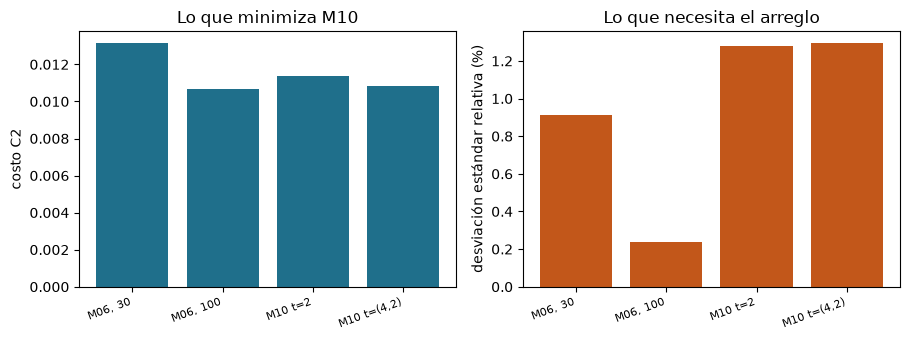

In [7]:
# costo C2 y desviación estándar relativa de las cuatro fases: M06 a 30 y 100 iteraciones, el refinamiento y
# el refinamiento con potencia
runs = {"M06, 30": start, "M06, 100": long06, "M10 t=2": refined, "M10 t=(4,2)": powered}
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.5))
a.bar(range(4), [cost.value_grad(r.phi)[0] for r in runs.values()], color="#1f6f8b")
b.bar(range(4), [r.history[-1]["rel_std"] for r in runs.values()], color="#c2571a")
for ax, label in ((a, "costo C2"), (b, "desviación estándar relativa (%)")):
    ax.set_xticks(range(4))
    ax.set_xticklabels(list(runs), rotation=20, ha="right", fontsize=8)
    ax.set_ylabel(label)
a.set_title("Lo que minimiza M10")
b.set_title("Lo que necesita el arreglo")
plt.tight_layout()
plt.show()

Los dos paneles discrepan sobre qué es mejor, que es la lección del refinamiento. A la izquierda las fases de M10 tienen los menores costos de la familia de 30 iteraciones (0,0114 y 0,0108 frente a 0,0131), y el lazo ponderado de 100 iteraciones, que nunca vio el costo, está en 0,0107. A la derecha el orden se invierte para la dispersión: los refinamientos están en 1,28 y 1,29 por ciento, sobre el 0,92 de partida y muy sobre el 0,24 de M06 a 100 iteraciones. El costo es un enunciado fiel de la eficiencia objetivo y un mal sustituto de la dispersión. La figura no muestra cuál sería el costo con una eficiencia objetivo más cercana a lo que alcanza el lazo, lo que explora la perilla de abajo.

### Pedir una eficiencia

Un lazo de proyección no tiene parámetro de eficiencia: la luz que llega a las trampas es la que permita el punto fijo del lazo. El costo sí tiene uno, $\eta$, y el argumento `efficiency` de M10 lo fija. La celda pide 0,5 y 0,7 de la potencia de entrada, con 150 iteraciones cada una, e imprime lo que entrega el método.

In [8]:
# el mismo costo con otra eficiencia objetivo: se le pide al método 0.5 y 0.7 de la potencia de entrada
dial = {}
for want in (0.5, 0.7):
    dial[want] = m10_cg.run(setup, target, budget=Budget(150), rng=Rng(1), efficiency=want).history[-1]
    print(f"objetivo {want}: eficiencia {dial[want]['efficiency']:.4f}  "
          f"desv. rel. {dial[want]['rel_std']:.2e} %")

objetivo 0.5: eficiencia 0.5000  desv. rel. 4.26e-14 %
objetivo 0.7: eficiencia 0.7000  desv. rel. 1.35e-10 %


El gráfico pone todas las corridas del notebook en un solo plano, con la eficiencia en el eje horizontal y la desviación estándar relativa, en escala logarítmica, en el vertical.

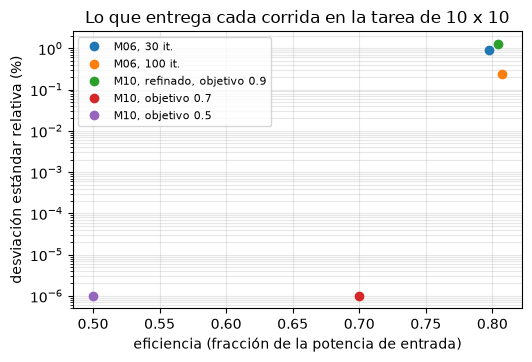

In [9]:
# todas las corridas en el plano de eficiencia y desviación estándar relativa (piso de 1e-6 % en el gráfico)
points = {"M06, 30 it.": start.history[-1], "M06, 100 it.": long06.history[-1],
          "M10, refinado, objetivo 0.9": refined.history[-1],
          "M10, objetivo 0.7": dial[0.7], "M10, objetivo 0.5": dial[0.5]}
fig, ax = plt.subplots(figsize=(5.8, 3.6))
for label, h in points.items():
    ax.semilogy(h["efficiency"], max(h["rel_std"], 1e-6), "o", label=label)
ax.set_xlabel("eficiencia (fracción de la potencia de entrada)")
ax.set_ylabel("desviación estándar relativa (%)")
ax.set_title("Lo que entrega cada corrida en la tarea de 10 x 10")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.show()

Las dos corridas con eficiencia pedida quedan sobre ella con cuatro cifras y tienen una desviación estándar relativa tan pequeña (4e-14 y 1e-10 por ciento) que se grafican en el piso del eje: cuando la eficiencia pedida está bajo lo que permite la física, el costo tiene un cero, y CG encuentra ahí un arreglo perfectamente uniforme. Las otras tres corridas (M06 dos veces y M10 con su objetivo por defecto de 0,9) caen en una banda de 0,77 a 0,81 de eficiencia y 0,2 a 2 por ciento de dispersión; ninguna se acerca a 0,9, así que el costo del objetivo 0,9 no puede ser cero. El gráfico no dice cuál es el mejor valor de $\eta$ para un experimento, ni que los puntos entre 0,7 y 0,8 sean alcanzables con dispersión cero; la curva completa entre los dos extremos es el tema del notebook `05-optimization/05-the-efficiency-uniformity-front`.

## Resultados

**Respuesta:** Minimizar un costo explícito compra control y cuesta iteraciones. Refinar la fase de M06 de 30 iteraciones con M10 baja el costo de 0,0131 a 0,0114 y sube la desviación estándar relativa de 0,92 a 1,28 por ciento, porque el costo también pide la eficiencia; las etapas con potencia $t = (4, 2)$ bajan el costo más, a 0,0108, y llevan la trampa más débil de 0,959 a 0,964 de la media. Al pedirle 0,5 y 0,7 de la potencia de entrada, M10 devuelve 0,5000 y 0,7000 con una desviación estándar relativa de 4,26e-14 y 1,35e-10 por ciento, algo que a un lazo de proyección no se le puede pedir. El lazo clásico sigue adelante con igual esfuerzo: M06 con 100 iteraciones tiene un costo de 0,0107, una eficiencia de 0,8070 y una dispersión de 0,24 por ciento, menores que cualquier resultado de M10 del notebook.

Lo que el notebook no muestra es una comparación con una implementación independiente del método de gradiente conjugado, que no existe entre las dependencias, ni los objetivos con forma donde el costo con potencia fue diseñado para importar.

## Resumen

- Refinar un holograma de GS ponderado con M10 baja el costo y sube la dispersión, porque el costo también pide la eficiencia.
- El costo con potencia cambia la trampa más débil y la más fuerte, como muestran los números de arriba, sin cambiar la eficiencia objetivo.
- Al pedirle 0,5 y 0,7 de la potencia de entrada, M10 devuelve exactamente eso con un arreglo perfectamente igual; al GS ponderado no se le puede pedir.
- Frente al lazo clásico M10 es más lento hacia un arreglo uniforme y el único que recibe una eficiencia como argumento.
- No existe una implementación de referencia fijada de M10 entre las dependencias.

## Referencias

- Harte et al. (2014). A conjugate gradient minimisation approach to generating holographic traps for ultracold atoms. Optics Express 22, 26548. https://doi.org/10.1364/OE.22.026548
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Chakravarthula et al. (2019). Wirtinger holography for near-eye displays. ACM Transactions on Graphics 38, 213. https://doi.org/10.1145/3355089.3356539